In [ ]:
import warnings
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.metrics import(silhouette_score)

from scipy.cluster.hierarchy import linkage, dendrogram



df=pd.read_csv('Wholesale customers data.csv')
df.head

<bound method NDFrame.head of      Channel  Region  Fresh   Milk  Grocery  Frozen  Detergents_Paper  \
0          2       3  12669   9656     7561     214              2674   
1          2       3   7057   9810     9568    1762              3293   
2          2       3   6353   8808     7684    2405              3516   
3          1       3  13265   1196     4221    6404               507   
4          2       3  22615   5410     7198    3915              1777   
..       ...     ...    ...    ...      ...     ...               ...   
435        1       3  29703  12051    16027   13135               182   
436        1       3  39228   1431      764    4510                93   
437        2       3  14531  15488    30243     437             14841   
438        1       3  10290   1981     2232    1038               168   
439        1       3   2787   1698     2510      65               477   

     Delicassen  
0          1338  
1          1776  
2          7844  
3          1788  
4          5185  
..          ...  
435        2204  
436        2346  
437        1867  
438        2125  
439          52  

[440 rows x 8 columns]>

In [ ]:
df.head()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185


In [ ]:
df.tail()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
435,1,3,29703,12051,16027,13135,182,2204
436,1,3,39228,1431,764,4510,93,2346
437,2,3,14531,15488,30243,437,14841,1867
438,1,3,10290,1981,2232,1038,168,2125
439,1,3,2787,1698,2510,65,477,52


In [ ]:
df.dtypes

,0
Channel,int64
Region,int64
Fresh,int64
Milk,int64
Grocery,int64
Frozen,int64
Detergents_Paper,int64
Delicassen,int64


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 440 entries, 0 to 439
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Channel           440 non-null    int64
 1   Region            440 non-null    int64
 2   Fresh             440 non-null    int64
 3   Milk              440 non-null    int64
 4   Grocery           440 non-null    int64
 5   Frozen            440 non-null    int64
 6   Detergents_Paper  440 non-null    int64
 7   Delicassen        440 non-null    int64
dtypes: int64(8)
memory usage: 27.6 KB


In [ ]:
df.isnull().sum()

,0
Channel,0
Region,0
Fresh,0
Milk,0
Grocery,0
Frozen,0
Detergents_Paper,0
Delicassen,0


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
scaler=StandardScaler()
df_scaled=scaler.fit_transform(df.drop('Channel',axis=1))
df_scaled

array([[ 0.59066829,  0.05293319,  0.52356777, ..., -0.58936716,
        -0.04356873, -0.06633906],
       [ 0.59066829, -0.39130197,  0.54445767, ..., -0.27013618,
         0.08640684,  0.08915105],
       [ 0.59066829, -0.44702926,  0.40853771, ..., -0.13753572,
         0.13323164,  2.24329255],
       ...,
       [ 0.59066829,  0.20032554,  1.31467078, ..., -0.54337975,
         2.51121768,  0.12145607],
       [ 0.59066829, -0.13538389, -0.51753572, ..., -0.41944059,
        -0.56977032,  0.21304614],
       [ 0.59066829, -0.72930698, -0.5559243 , ..., -0.62009417,
        -0.50488752, -0.52286938]])

In [ ]:
X_scaled_df=pd.DataFrame(df_scaled,columns=df.columns[1:])
X_scaled_df.head()

,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,0.590668,0.052933,0.523568,-0.041115,-0.589367,-0.043569,-0.066339
1,0.590668,-0.391302,0.544458,0.170318,-0.270136,0.086407,0.089151
2,0.590668,-0.447029,0.408538,-0.028157,-0.137536,0.133232,2.243293
3,0.590668,0.100111,-0.624020,-0.392977,0.687144,-0.498588,0.093411
4,0.590668,0.840239,-0.052396,-0.079356,0.173859,-0.231918,1.299347


In [ ]:
print("First five scaled records:")
display(X_scaled_df.head())
print("\nLast five scaled records:")
display(X_scaled_df.tail())

First five scaled records:


,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,0.590668,0.052933,0.523568,-0.041115,-0.589367,-0.043569,-0.066339
1,0.590668,-0.391302,0.544458,0.170318,-0.270136,0.086407,0.089151
2,0.590668,-0.447029,0.408538,-0.028157,-0.137536,0.133232,2.243293
3,0.590668,0.100111,-0.624020,-0.392977,0.687144,-0.498588,0.093411
4,0.590668,0.840239,-0.052396,-0.079356,0.173859,-0.231918,1.299347



Last five scaled records:


,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
435,0.590668,1.401312,0.848446,0.850760,2.075222,-0.566831,0.241091
436,0.590668,2.155293,-0.592142,-0.757165,0.296561,-0.585519,0.291501
437,0.590668,0.200326,1.314671,2.348386,-0.543380,2.511218,0.121456
438,0.590668,-0.135384,-0.517536,-0.602514,-0.419441,-0.569770,0.213046
439,0.590668,-0.729307,-0.555924,-0.573227,-0.620094,-0.504888,-0.522869


In [ ]:
print("\nScaled feature standard deviations(approximately one):")
print(X_scaled_df.std(ddof=0))

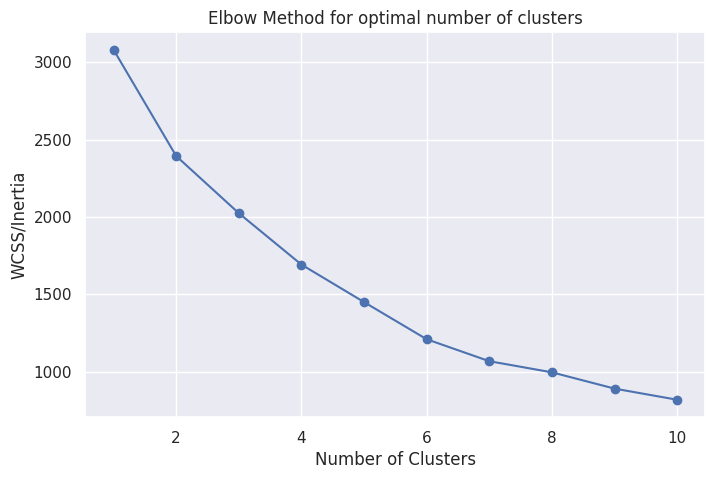

In [ ]:
wcss=[]
K_value=range(1,11)

for k in K_value:
    kmeans=KMeans(n_clusters=k,random_state=42,n_init=10)
    kmeans.fit(X_scaled_df)
    wcss.append(kmeans.inertia_)

plt.figure(figsize=(8,5))
plt.plot(K_value, wcss, marker="o")
plt.title("Elbow Method for optimal number of clusters")
plt.xlabel("Number of Clusters")
plt.ylabel("WCSS/Inertia")
plt.show()

In [ ]:
silhouette_values = []

for k in range(2, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X_scaled_df)
    labels = model.labels_
    silhouette_values.append(silhouette_score(X_scaled_df, labels))

silhouette_table = pd.DataFrame({
    "Number of clusters": list(range(2, 11)),
    "Silhouette score": silhouette_values
})

display(silhouette_table)

,Number of clusters,Silhouette score
0,2,0.528863
1,3,0.300913
2,4,0.310396
3,5,0.318165
4,6,0.316885
5,7,0.328031
6,8,0.325883
7,9,0.284480
8,10,0.296475


In [ ]:
suggested_k = int(
    silhouette_table.loc[silhouette_table['Silhouette score'].idxmax(), 'Number of clusters']
)

print("k suggested by the highest silhouette score:", suggested_k)

k suggested by the highest silhouette score: 2


In [ ]:
K = suggested_k
kmeans_model = KMeans(n_clusters=K, random_state=42, n_init=10)
k_means_labels = kmeans_model.fit_predict(X_scaled_df)

In [ ]:
df_Kmeans=df.copy()
df_Kmeans['Cluster']=k_means_labels
print("K-means clustering completed.")
print("\nNumber of customers in each cluster:")
print(df_Kmeans['Cluster'].value_counts())
df_Kmeans.head()

K-means clustering completed.

Number of customers in each cluster:
Cluster
0    401
1     39
Name: count, dtype: int64


,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen,Cluster
0,2,3,12669,9656,7561,214,2674,1338,0
1,2,3,7057,9810,9568,1762,3293,1776,0
2,2,3,6353,8808,7684,2405,3516,7844,0
3,1,3,13265,1196,4221,6404,507,1788,0
4,2,3,22615,5410,7198,3915,1777,5185,0


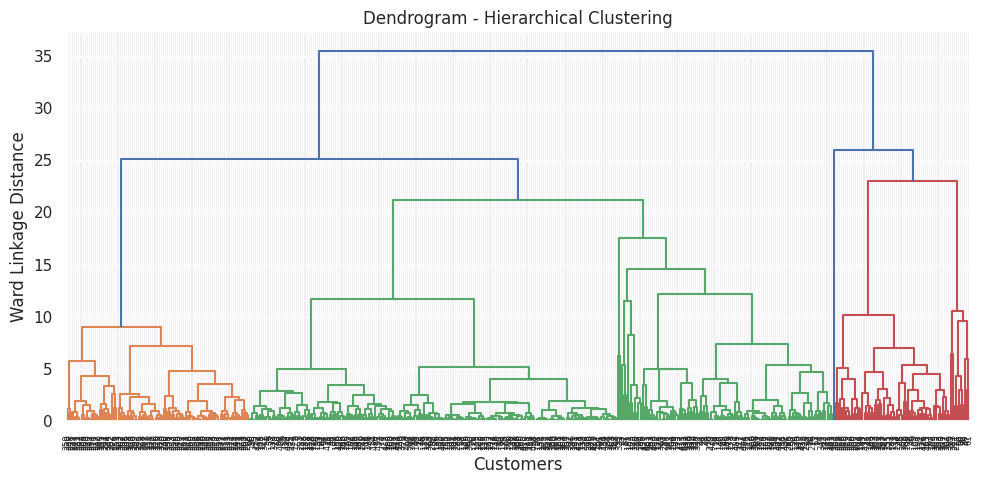

In [ ]:
Z = linkage(X_scaled_df, method='ward', metric='euclidean')

plt.figure(figsize=(10, 5))
dendrogram(Z, leaf_rotation=90, leaf_font_size=6)
plt.title('Dendrogram - Hierarchical Clustering')
plt.xlabel('Customers')
plt.ylabel('Ward Linkage Distance')
plt.tight_layout()
plt.show()

<module 'matplotlib.pyplot' from '/usr/local/lib/python3.13/dist-packages/matplotlib/pyplot.py'>

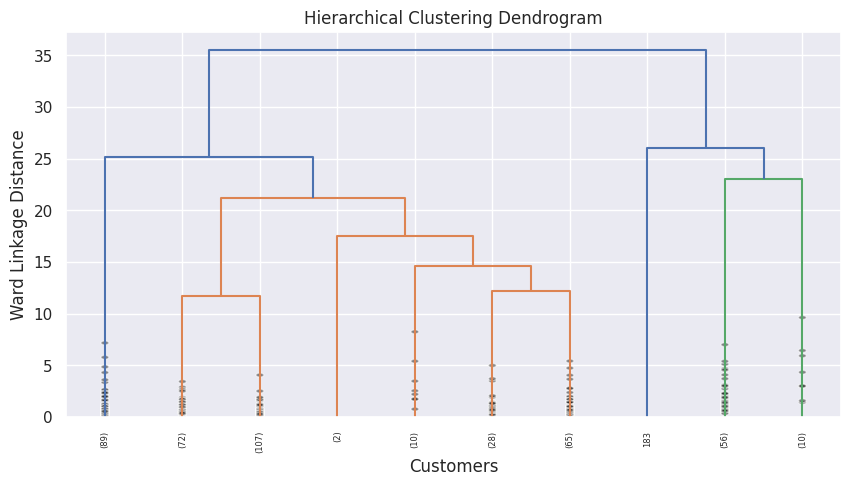

In [ ]:
plt.figure(figsize=(10, 5))
dendrogram(Z, truncate_mode='lastp', p=10, show_contracted=True, leaf_rotation=90, leaf_font_size=6)
plt.title('Hierarchical Clustering Dendrogram')
plt.xlabel('Customers')
plt.ylabel('Ward Linkage Distance')
plt

In [ ]:
pca=PCA(n_components=2)
X_pca=pca.fit_transform(X_scaled_df)
print("Variance explained by each principal component:")
print(f"{pca.explained_variance_ratio_.sum()*100:.2f}%")
plot_df=pd.DataFrame(X_pca,columns=['PC1','PC2'])
plot_df.head()

Variance explained by each principal component:
62.15%


,PC1,PC2
0,0.205470,-0.268756
1,0.446228,-0.294124
2,0.824133,0.847760
3,-0.766022,0.686296
4,0.179955,1.305515


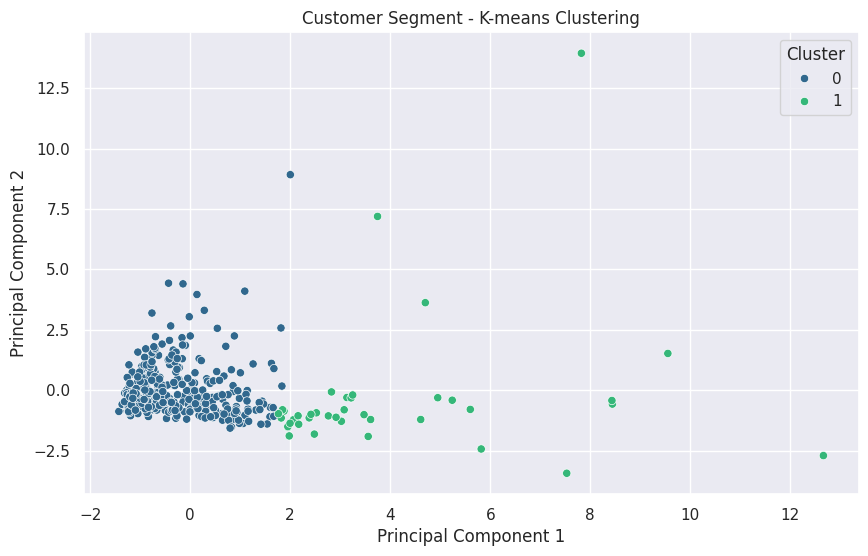

In [ ]:
plt.figure(figsize=(10, 6))
sns.scatterplot(x='PC1', y='PC2', data=plot_df, hue=df_Kmeans['Cluster'], palette='viridis')
plt.title("Customer Segment - K-means Clustering")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title='Cluster')
plt.show()

In [ ]:
def evaluate_clustering(X_data,labels,model_name):
  return {
    'Algorithm':model_name,
    'Number of Clusters':len(np.unique(labels)),
    'Silhouette Score':silhouette_score(X_data,labels)
  }

In [ ]:
# 1. Fit Agglomerative Clustering to get the missing hierarchical labels
hierarchical_model = AgglomerativeClustering(n_clusters=2, linkage='ward')
hierarchical_labels = hierarchical_model.fit_predict(X_scaled_df)

# 2. Evaluate both algorithms
c_kmeans = evaluate_clustering(X_scaled_df, k_means_labels, 'K-means')
c_hierarchical = evaluate_clustering(X_scaled_df, hierarchical_labels, 'Hierarchical clustering')

# 3. Create the comparison DataFrame
comparison_df = pd.DataFrame([c_kmeans, c_hierarchical])

print("Comparison of clustering algorithms:")
display(comparison_df.round(4))

Comparison of clustering algorithms:


,Algorithm,Number of Clusters,Silhouette Score
0,K-means,2,0.5289
1,Hierarchical clustering,2,0.4101


In [ ]:
# Get cluster value counts for both algorithms
kmeans_counts = df_Kmeans['Cluster'].value_counts().sort_index()
hierarchical_counts = pd.Series(hierarchical_labels).value_counts().sort_index()

# Combine them into a single DataFrame
cluster_sizes = pd.DataFrame({
    'K-means': kmeans_counts,
    'Hierarchical': hierarchical_counts
}).fillna(0).astype(int)

print('Cluster sizes:')
display(cluster_sizes)

Cluster sizes:


,K-means,Hierarchical
0,401,67
1,39,373


In [ ]:
# Select only the numeric spending features
spending_features = df.columns[2:]
k_means_profile = df[spending_features].copy()
k_means_profile['Cluster'] = df_Kmeans['Cluster']

# Group by cluster and calculate the mean spending, rounded to 2 decimal places
k_means_means = k_means_profile.groupby('Cluster').mean().round(2)

print('Average spending profile of K-means clusters:')
display(k_means_means)

Average spending profile of K-means clusters:


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
Cluster,,,,,,
0,11992.65,4281.81,5817.94,3059.51,1787.01,1305.37
1,12078.92,21367.95,29886.38,3199.64,14134.97,3781.77
